# PRT (Bus) Stops
For college students and city-dwellers in general, public transport is THE way to get around. According to the United States Census Bureau, every year over 10% of Pittsburgh residents commute using the Public Regional Transport System, and that's not even counting how many people commute from outside of Pittsburgh. 

I'll be focusing on internal public transport, specifically buses, for my submetric. <br>
Going off of the above, it makes sense for a good neighborhood in Pittsburgh to have abundant bus stops. In this analysis I will be excluding the incline and the light rail because "who decides where to live based on whether or not it has an incline within walking distance??" <br>

[talk more technical detai lhere]# PRT (Bus) Stops
For college students and city-dwellers in general, public transport is THE way to get around. According to the United States Census Bureau, every year over 10% of Pittsburgh residents commute using the Public Regional Transport System, and that's not even counting how many people commute from outside of Pittsburgh. 

I'll be focusing on internal public transport, specifically buses, for my submetric. <br>
Going off of the above, it makes sense for a good neighborhood in Pittsburgh to have abundant bus stops. In this analysis I will be excluding the incline and the light rail because "who decides where to live based on whether or not it has an incline within walking distance??" <br>

We'll use the PRT type and neighborhood columns to sort and analyze the data.

In [102]:
import pandas as pd
import matplotlib.pyplot as plt

# Import my chosen csv
# %cd /ihome/cmpinf0010-sec1010_2026f/lyy7/Lyakovlev Submetric
stops = pd.read_csv("Transit_Stops.csv")import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Import my chosen csv
stops = pd.read_csv("Transit_Stops.csv")

# Show the new dataset assignment was successful
bus_stops = stops[(stops["mode"] == "BUS") & (stops["muni"] == "Pittsburgh city (Allegheny, PA)")][["mode", "stop_name", "hood"]]
bus_stops.head()

,mode,stop_name,hood
0,BUS,26TH ST AT PENN AVE FS (SPRING WAY),Strip District
1,BUS,28TH ST AT LIBERTY AVE,Polish Hill
2,BUS,32ND ST AT SPRING WAY,Strip District
3,BUS,40TH ST AT BUTLER ST,Lower Lawrenceville
4,BUS,40TH ST AT DAVIDSON ST FS,Central Lawrenceville


I have created a new dataframe from the original that uses two query masks: one that limits the rows to bus stops, and one that limits those rows to Pittsburgh city stops, since I noticed the frame also includes nearby counties. I only really need the neighborhood the stop is in, but I will also keep the mode and stop name columns for differentiation. <br>

Now, it's time to start breaking it down!

In [104]:
# Use a dictionary to count how many times each neighborhood appears
dic = {}
for index, row in bus_stops.iterrows():
    neighborhood = row["hood"]

    if neighborhood not in dic:
        dic[neighborhood] = 1
    else:
        dic[neighborhood] += 1
        
# Sort in descending order based on stop count
# Sorted method automatically does this, but we have to use a one-line function to look at the number assigned to each key
dic = dict(sorted(dic.items(), key=lambda item: item[1]))

for neighborhood in dic:
    print(neighborhood, ":" , dic[neighborhood], "stops")

Ridgemont : 2 stops
Swisshelm Park : 3 stops
St. Clair : 3 stops
New Homestead : 4 stops
East Carnegie : 4 stops
North Shore : 6 stops
Chartiers City : 6 stops
Hays : 7 stops
Arlington-Arlington Heights : 8 stops
Central Oakland : 9 stops
Fairywood : 9 stops
Oakwood : 9 stops
Esplen : 9 stops
Regent Square : 10 stops
Fineview : 10 stops
Mt. Oliver : 10 stops
Allegheny West : 11 stops
Bedford Dwellings : 11 stops
Bon Air : 11 stops
South Shore : 11 stops
Duquesne Heights : 12 stops
Overbrook : 13 stops
West End : 13 stops
Banksville : 13 stops
Beechview : 15 stops
Friendship : 16 stops
Glen Hazel : 16 stops
California-Kirkbride : 16 stops
Central Northside : 16 stops
Point Breeze North : 17 stops
South Oakland : 17 stops
Chateau : 19 stops
Allentown : 19 stops
Windgap : 19 stops
Homewood West : 21 stops
Elliott : 21 stops
Westwood : 21 stops
Upper Hill : 22 stops
Northview Heights : 22 stops
Bluff : 23 stops
Summer Hill : 23 stops
Strip District : 24 stops
Highland Park : 24 stops
Stant

Okay, that's a bit long. 90 neighborhoods is nothing to sneeze at! <br>
Let's graph this out. I'm only doing the top 20 neighborhoods because all 90 would not be readable at all.

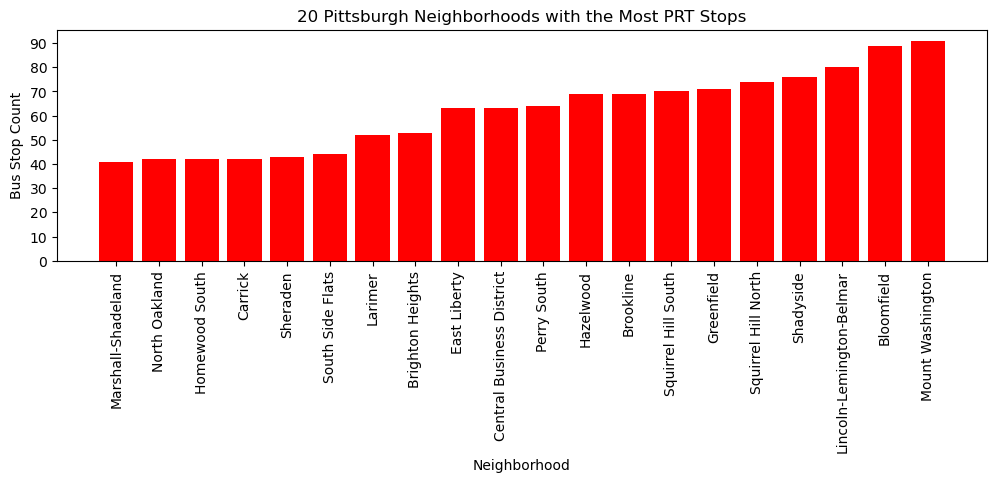

In [116]:
# Use matplotlib keys and values to plot a bar graph of the dictionary
# Replace() used to format neighborhood names such that they don't overlap
neighborhoods = list(dic.keys())[-20:]
stops = list(dic.values())[-20:]

plt.figure(figsize=(12, 3))
plt.bar(neighborhoods, stops, color = "red")
plt.title("20 Pittsburgh Neighborhoods with the Most PRT Stops")
plt.xlabel("Neighborhood")
plt.ylabel("Bus Stop Count")

# Use numpy just to help with formatting
plt.xticks(rotation=90)
plt.yticks(np.arange(0, 100, 10))

plt.show()

Going solely off of the number of bus stops, <b> Mount Washington </b> would be the best neighborhood!

This isn't perfect, though. Is just the number of bus stops in a neighborhood enough to determine if it's convenient to live there? One neighborhood may have 10 versus another with 1, but chances are that first neighborhood is far larger than the second. 

We can take this a step further by looking at neighborhood PRT Bus Stops <b>by square mile.</b>

# PRT Bus Stops Per Square Mile

We'll need to bring in a new dataframe for these calculations. Don't worry, it's a simple one: City of Pittsburgh GIS Data HUB's <b> "Neighborhoods"</b> dataframe. <br>
Luckily, we only need to grab the neighborhood and square mileage columns.

In [113]:
areas = pd.read_csv("Neighborhoods_.csv")[["hood","sqmiles"]]
areas.head()

,hood,sqmiles
0,Point Breeze North,0.301921
1,Squirrel Hill North,1.223409
2,Garfield,0.457385
3,Bedford Dwellings,0.175674
4,Knoxville,0.299625
